In [10]:
import sys

sys.path.append("../src")

In [11]:
import matplotlib.pyplot as plt
import numpy as np

from geometry import sample_convex_shapes

In [12]:
s = 1.5
r0 = 10 * s
Ny, Nx = int(100 * s), int(400 * s)
cx, cy = int(100 * s), int(50 * s)

In [13]:
masks, radii, margins = sample_convex_shapes(
    20,
    Ny,
    Nx,
    cx,
    cy,
    r0=r0,
    eps=0.08,
    ell=1.0,
    rng=np.random.default_rng(0),
    a1_max=0.3,
    a2_max=0.18,
    tol=-0.2,
)

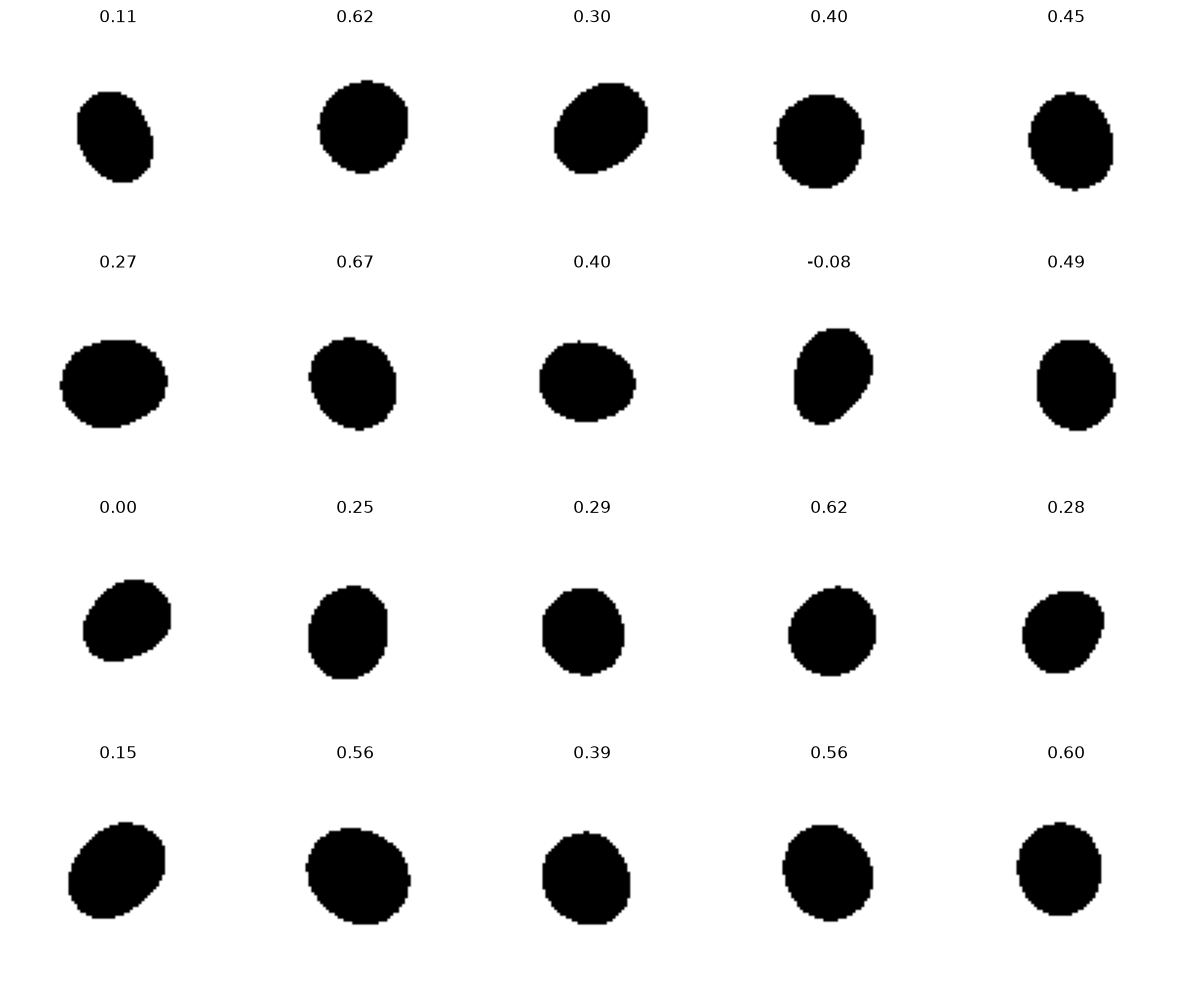

In [14]:
half = int(2.5 * r0)  # crop window around the shape
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for k, ax in enumerate(axes.flat[: len(masks)]):
    ax.imshow(
        masks[k][cy - half : cy + half, cx - half : cx + half],
        origin="lower",
        cmap="gray_r",
    )
    ax.set_title(f"{margins[k]:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [15]:
import time
from solvers.lbm import run

masks, radii, margins = sample_convex_shapes(
    3,
    Ny,
    Nx,
    cx,
    cy,
    r0=r0,
    eps=0.08,
    ell=1.0,
    rng=np.random.default_rng(0),
    a1_max=0.3,
    a2_max=0.18,
    tol=-0.2,
)

results = []
for k, mask in enumerate(masks):
    t0 = time.perf_counter()
    rho, u, _, steps = run(Nx=Nx, Ny=Ny, D=2 * r0, Re=20, n_steps=60_000, mask=mask)
    elapsed = time.perf_counter() - t0
    results.append((rho, u))
    print(f"shape {k}: {steps} steps, {elapsed:.0f} s, converged={steps < 60_000}")

shape 0: 17000 steps, 122 s, converged=True
shape 1: 17500 steps, 123 s, converged=True
shape 2: 16500 steps, 115 s, converged=True
